In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

UNIFIED_FONT_FAMILY = 'DejaVu Sans'
# Adjust these font sizes manually to tune the exported figures.
UNIFIED_FONT_SIZE = 13
AXIS_LABEL_FONT_SIZE = 13
TITLE_FONT_SIZE = 13
TICK_FONT_SIZE = 12
ANNOTATION_FONT_SIZE = 9
LEGEND_FONT_SIZE = 12
MARKER_AREA_MIN = 120
MARKER_AREA_MAX = 220
PANEL_WSPACE = 0.34
FIGURE_BOTTOM_MARGIN = 0.22
LEGEND_VERTICAL_OFFSET = -0.06
FIGURE_FACE = 'white'
AXES_FACE = 'white'
AXIS_TEXT_COLOR = '#4A4A4A'
FRAME_COLOR = '#4A4A4A'
GREY = '#878787'
MATTE_BLUE = '#2F4F6F'
LIGHT_BLUE = '#BDD9E8'
PALE_BLUE = '#DBEEF5'
EDGE_COLOR = '#173042'
GRID_COLOR = '#edf2f7'
BACKGROUND = AXES_FACE
LEGEND_FACE = 'white'
LEGEND_EDGE = FRAME_COLOR
ERRORBAR_COLOR = '#6f6f6f'
BAR_MAC_COLOR = '#B6B6B6'
BAR_AC_COLOR = '#B6B6B6'
BAR_AC_HATCH_COLOR = '#FFFFFF'
BAR_AC_HATCH = '///'
BAR_AC_HATCH_LINEWIDTH = 0.7
HIGHLIGHT_RED = '#d62728'

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = UNIFIED_FONT_FAMILY
mpl.rcParams['font.size'] = UNIFIED_FONT_SIZE
mpl.rcParams['axes.labelsize'] = AXIS_LABEL_FONT_SIZE
mpl.rcParams['axes.titlesize'] = TITLE_FONT_SIZE
mpl.rcParams['xtick.labelsize'] = TICK_FONT_SIZE
mpl.rcParams['ytick.labelsize'] = TICK_FONT_SIZE
mpl.rcParams['legend.fontsize'] = LEGEND_FONT_SIZE
mpl.rcParams['axes.labelcolor'] = AXIS_TEXT_COLOR
mpl.rcParams['axes.edgecolor'] = FRAME_COLOR
mpl.rcParams['xtick.color'] = AXIS_TEXT_COLOR
mpl.rcParams['ytick.color'] = AXIS_TEXT_COLOR
mpl.rcParams['figure.facecolor'] = FIGURE_FACE
mpl.rcParams['savefig.facecolor'] = FIGURE_FACE
mpl.rcParams['axes.facecolor'] = AXES_FACE


def style_single_axis(ax, xlabel=None, ylabel=None):
    ax.set_facecolor(AXES_FACE)
    ax.set_axisbelow(True)
    for spine_name in ['left', 'right', 'top', 'bottom']:
        ax.spines[spine_name].set_visible(True)
        ax.spines[spine_name].set_color(FRAME_COLOR)
        ax.spines[spine_name].set_linewidth(1.0)
    ax.tick_params(axis='x', colors=AXIS_TEXT_COLOR, length=0)
    ax.tick_params(axis='y', colors=AXIS_TEXT_COLOR)
    if xlabel is not None:
        ax.set_xlabel(xlabel, color=AXIS_TEXT_COLOR, fontweight='bold')
    if ylabel is not None:
        ax.set_ylabel(ylabel, color=AXIS_TEXT_COLOR, fontweight='bold')


def style_dual_axis(
    ax_left,
    ax_right,
    xlabel=None,
    ylabel_left=None,
    ylabel_right=None,
    left_color=AXIS_TEXT_COLOR,
    right_color=MATTE_BLUE,
):
    style_single_axis(ax_left, xlabel=xlabel, ylabel=None)
    ax_left.tick_params(axis='y', colors=left_color)
    ax_left.spines['left'].set_color(left_color)
    if ylabel_left is not None:
        ax_left.set_ylabel(ylabel_left, color=left_color, fontweight='bold')

    ax_right.patch.set_alpha(0)
    ax_right.tick_params(axis='y', colors=right_color)
    ax_right.spines['right'].set_visible(True)
    ax_right.spines['right'].set_color(right_color)
    ax_right.spines['right'].set_linewidth(1.0)
    ax_right.spines['top'].set_color(FRAME_COLOR)
    ax_right.spines['top'].set_linewidth(1.0)
    if ylabel_right is not None:
        ax_right.set_ylabel(ylabel_right, color=right_color, fontweight='bold')


def style_legend(legend):
    legend.get_frame().set_facecolor(LEGEND_FACE)
    legend.get_frame().set_edgecolor(LEGEND_EDGE)
    legend.get_frame().set_linewidth(1.0)
    legend.get_title().set_color(AXIS_TEXT_COLOR)
    legend.get_title().set_fontsize(LEGEND_FONT_SIZE)
    legend.get_title().set_ha('center')
    legend._legend_box.align = 'center'
    for text in legend.get_texts():
        text.set_color(AXIS_TEXT_COLOR)
        text.set_fontsize(LEGEND_FONT_SIZE)
        text.set_ha('center')


/home/alex/snn_for_bts/brain_to_text/analyses
Records included in the grouped PER comparison:
  500k:
    MLP: PER=0.2522 +/- 0.0053, energy=583.36 uJ, MACs=127M
    LSTM: PER=0.2141 +/- 0.0056, energy=550.55 uJ, MACs=120M
    GRU: PER=0.2237 +/- 0.0230, energy=488.19 uJ, MACs=106M
    TCN: PER=0.1682 +/- 0.0047, energy=447.61 uJ, MACs=97M
    Ours: PER=0.1425 +/- 0.0036, energy=221.85 uJ, MACs=46M
  2M:
    MLP: PER=0.2200 +/- 0.0043, energy=2196.01 uJ, MACs=477M
    LSTM: PER=0.1526 +/- 0.0034, energy=2317.57 uJ, MACs=504M
    GRU: PER=0.1366 +/- 0.0054, energy=2200.95 uJ, MACs=478M
    TCN: PER=0.1509 +/- 0.0024, energy=2317.74 uJ, MACs=504M
    Ours: PER=0.1235 +/- 0.0037, energy=588.02 uJ, MACs=120M
  5M:
    MLP: PER=0.2023 +/- 0.0044, energy=4969.80 uJ, MACs=1080M
    LSTM: PER=0.1092 +/- 0.0023, energy=5043.82 uJ, MACs=1096M
    GRU: PER=0.1199 +/- 0.0033, energy=4954.24 uJ, MACs=1076M
    TCN: PER=0.1418 +/- 0.0045, energy=5318.13 uJ, MACs=1156M
    Ours: PER=0.1123 +/- 0.0038

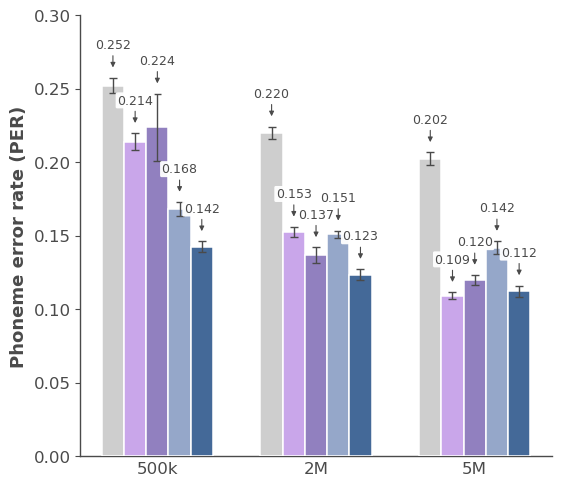

Saved per_model_per_barplot.png


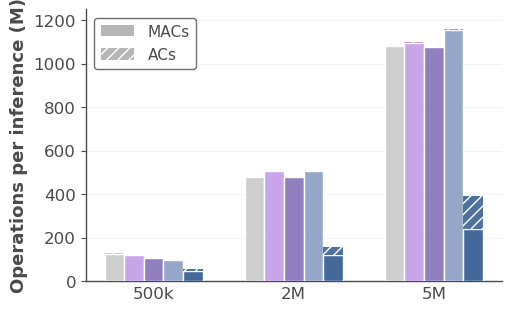

Saved per_model_macs_acs_stacked_barplot.png


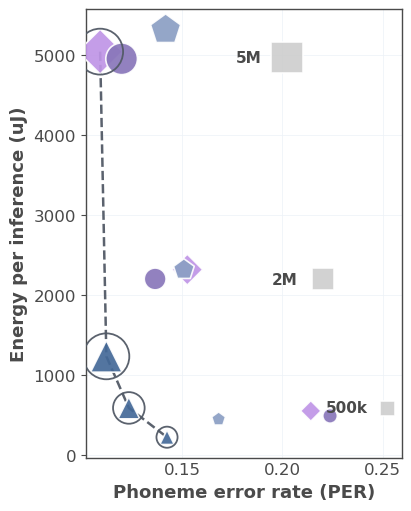

Saved per_model_energy_per_bubble.png


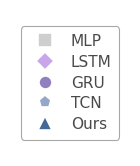

Saved per_model_model_legend.png


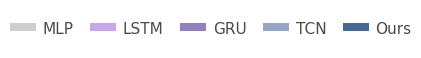

Saved per_model_color_legend_row.png


In [34]:
import pandas as pd
from pathlib import Path

NOTEBOOK_NAME = 'per_model_eval_vis.ipynb'


def resolve_notebook_dir():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd / 'analyses'):
        if (candidate / NOTEBOOK_NAME).exists():
            return candidate
    return cwd


NOTEBOOK_DIR = resolve_notebook_dir()
FIGURES_DIR = NOTEBOOK_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f'Notebook directory: {NOTEBOOK_DIR}')
print(f'Figure exports directory: {FIGURES_DIR}')

results = [
    {
        'budget': '500k',
        'models': [
            {'model': 'Ours', 'per': '0.1425 ± 0.0036', 'energy_uJ': 221.85, 'macs': '46M', 'acs': '10.58M'},
            {'model': 'TCN', 'per': '0.1682 ± 0.0047', 'energy_uJ': 447.61, 'macs': '97M', 'acs': '0.13M'},
            {'model': 'LSTM', 'per': '0.2141 ± 0.0056', 'energy_uJ': 550.55, 'macs': '120M', 'acs': '0.18M'},
            {'model': 'GRU', 'per': '0.2237 ± 0.0230', 'energy_uJ': 488.19, 'macs': '106M', 'acs': '0.35M'},
            {'model': 'MLP', 'per': '0.2522 ± 0.0053', 'energy_uJ': 583.36, 'macs': '127M', 'acs': '0.12M'},
        ],
    },
    {
        'budget': '2M',
        'models': [
            {'model': 'Ours', 'per': '0.1235 ± 0.0037', 'energy_uJ': 588.02, 'macs': '120M', 'acs': '37.85M'},
            {'model': 'TCN', 'per': '0.1509 ± 0.0024', 'energy_uJ': 2317.74, 'macs': '504M', 'acs': '0.62M'},
            {'model': 'LSTM', 'per': '0.1526 ± 0.0034', 'energy_uJ': 2317.57, 'macs': '504M', 'acs': '0.46M'},
            {'model': 'GRU', 'per': '0.1366 ± 0.0054', 'energy_uJ': 2200.95, 'macs': '478M', 'acs': '0.69M'},
            {'model': 'MLP', 'per': '0.2200 ± 0.0043', 'energy_uJ': 2196.01, 'macs': '477M', 'acs': '0.43M'},
        ],
    },
    {
        'budget': '5M',
        'models': [
            {'model': 'Ours', 'per': '0.1123 ± 0.0038', 'energy_uJ': 1233.34, 'macs': '238M', 'acs': '151.98M'},
            {'model': 'TCN', 'per': '0.1418 ± 0.0045', 'energy_uJ': 5318.13, 'macs': '1156M', 'acs': '0.57M'},
            {'model': 'LSTM', 'per': '0.1092 ± 0.0023', 'energy_uJ': 5043.82, 'macs': '1096M', 'acs': '1.81M'},
            {'model': 'GRU', 'per': '0.1199 ± 0.0033', 'energy_uJ': 4954.24, 'macs': '1076M', 'acs': '1.01M'},
            {'model': 'MLP', 'per': '0.2023 ± 0.0044', 'energy_uJ': 4969.80, 'macs': '1080M', 'acs': '0.71M'},
        ],
    },
]

comparison_style = {
    "MLP":  {"color": "#CECECEFF", "marker": "s"},  # light grey
    "LSTM": {"color": "#BF95E6D6", "marker": "D"},  # soft lavender
    "GRU":  {"color": "#8976BAED", "marker": "o"},  # pale blue-grey
    "TCN":  {"color": "#8B9FC4E9", "marker": "p"},  # slate blue-purple
    "Ours": {"color": "#446998", "marker": "^"},  # strong blue
}
family_legend_order = ['MLP', 'LSTM', 'GRU', 'TCN', 'Ours']


def parse_mean_std(value):
    mean_str, std_str = [part.strip() for part in str(value).split('±')]
    return float(mean_str), float(std_str)


def parse_compact_number(value):
    value = str(value).strip().replace(',', '')
    suffix = value[-1].upper()
    multipliers = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    if suffix in multipliers:
        return float(value[:-1]) * multipliers[suffix]
    return float(value)


records = []
for budget_entry in results:
    budget = budget_entry['budget']
    for model_entry in budget_entry['models']:
        per_mean, per_std = parse_mean_std(model_entry['per'])
        records.append(
            {
                'budget': budget,
                'budget_value': parse_compact_number(budget),
                'model_family': model_entry['model'],
                'display_name': model_entry['model'],
                'per_mean': per_mean,
                'per_std': per_std,
                'energy_uJ': float(model_entry['energy_uJ']),
                'macs': parse_compact_number(model_entry['macs']),
                'acs': parse_compact_number(model_entry['acs']),
            }
        )

plot_df = pd.DataFrame(records)
plot_df = plot_df.sort_values(['budget_value', 'model_family']).reset_index(drop=True)


def scale_bubble_sizes(series, size_min=110, size_max=520):
    series = series.astype(float)
    if np.isclose(series.max(), series.min()):
        return pd.Series(np.full(len(series), (size_min + size_max) / 2.0), index=series.index)
    return size_min + (series - series.min()) / (series.max() - series.min()) * (size_max - size_min)


def lighten_color(color, blend=0.38):
    base_rgb = np.array(mpl.colors.to_rgb(color), dtype=float)
    return mpl.colors.to_hex(base_rgb * (1.0 - blend) + np.ones(3) * blend)


def build_model_legend_handles(families, marker_size=9):
    handles = []
    for family in families:
        style = comparison_style[family]
        handles.append(
            mpl.lines.Line2D(
                [], [],
                linestyle='None',
                marker=style['marker'],
                markersize=marker_size,
                markerfacecolor=style['color'],
                markeredgecolor='white',
                markeredgewidth=1.2,
                label=family,
            )
        )
    return handles


def build_model_color_handles(families):
    handles = []
    for family in families:
        style = comparison_style[family]
        handles.append(
            mpl.patches.Patch(
                facecolor=style['color'],
                edgecolor='none',
                label=family,
            )
        )
    return handles


def compute_pareto_frontier(df):
    frontier_mask = []
    for row in df.itertuples():
        dominated = False
        for candidate in df.itertuples():
            if candidate.Index == row.Index:
                continue
            if (
                candidate.per_mean <= row.per_mean
                and candidate.energy_uJ <= row.energy_uJ
                and (
                    candidate.per_mean < row.per_mean
                    or candidate.energy_uJ < row.energy_uJ
                )
            ):
                dominated = True
                break
        frontier_mask.append(not dominated)
    return df.loc[frontier_mask].sort_values(['per_mean', 'energy_uJ']).reset_index(drop=True)


plot_df['bubble_size'] = scale_bubble_sizes(plot_df['budget_value'])
comparison_df = plot_df.copy()
pareto_frontier_df = compute_pareto_frontier(comparison_df)
legend_families = [family for family in family_legend_order if family in comparison_df['model_family'].unique()]
capacity_values = [budget for budget in sorted(comparison_df['budget'].unique(), key=parse_compact_number)]

# Individual panel sizes for manual tuning.
per_bar_figure_size = (5.5, 4.75)
compute_bar_figure_size = (5.0, 3.0)
per_energy_bubble_figure_size = (4.0, 5.0)
model_legend_figure_size = (1.55, 1.90)
model_legend_marker_size = 9.4
model_color_row_figure_size = (4.8, 0.5)
model_color_row_handle_length = 1.55
model_color_row_handle_height = 0.32
model_color_row_column_spacing = 1.0
export_dpi = 900
mlp_budget_label_offsets = {
    '500k': (-14, 0),
    '2M': (-18, 0),
    '5M': (-18, 0),
}

print('Records included in the grouped PER comparison:')
for budget in capacity_values:
    budget_rows = comparison_df[comparison_df['budget'] == budget].copy()
    budget_rows['family_order'] = budget_rows['model_family'].apply(
        lambda family: family_legend_order.index(family) if family in family_legend_order else len(family_legend_order)
    )
    budget_rows = budget_rows.sort_values(['family_order', 'per_mean'])
    print(f'  {budget}:')
    for row in budget_rows.itertuples(index=False):
        print(f"    {row.display_name}: PER={row.per_mean:.4f} +/- {row.per_std:.4f}, energy={row.energy_uJ:.2f} uJ, MACs={row.macs / 1e6:.0f}M")

print('Pareto frontier configurations (minimize PER and energy):')
for row in pareto_frontier_df.itertuples(index=False):
    print(f"  {row.budget} {row.display_name}: PER={row.per_mean:.4f}, energy={row.energy_uJ:.2f} uJ")

bar_figure_size = per_bar_figure_size
bar_save_path = FIGURES_DIR / 'per_model_per_barplot.png'
fig, ax = plt.subplots(figsize=bar_figure_size, constrained_layout=True)
fig.patch.set_facecolor(FIGURE_FACE)
style_single_axis(ax, xlabel=None, ylabel='Phoneme error rate (PER)')
ax.set_ylim(0.0, 0.30)
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

group_centers = np.arange(len(capacity_values), dtype=float)
bar_width = 0.14
offsets = np.linspace(-(len(legend_families) - 1) / 2.0, (len(legend_families) - 1) / 2.0, len(legend_families)) * bar_width
arrow_tip_offset = 0.007
arrow_length = 0.008
value_label_offset = 0.018
all_bar_tops = []

for family_index, family in enumerate(legend_families):
    family_rows = comparison_df[comparison_df['model_family'] == family].set_index('budget').reindex(capacity_values)
    x_positions = group_centers + offsets[family_index]
    heights = family_rows['per_mean'].to_numpy(dtype=float)
    errors = family_rows['per_std'].fillna(0.0).to_numpy(dtype=float)
    valid = ~np.isnan(heights)
    if not np.any(valid):
        continue
    color = comparison_style[family]['color']
    ax.bar(
        x_positions[valid],
        heights[valid],
        width=bar_width,
        color=color,
        edgecolor='white',
        linewidth=1.1,
        label=family,
        zorder=3,
    )
    ax.errorbar(
        x_positions[valid],
        heights[valid],
        yerr=errors[valid],
        fmt='none',
        ecolor=AXIS_TEXT_COLOR,
        elinewidth=1.0,
        capsize=3,
        zorder=4,
    )
    for x_position, height, error in zip(x_positions[valid], heights[valid], errors[valid]):
        arrow_tip_y = height + error + arrow_tip_offset
        arrow_tail_y = arrow_tip_y + arrow_length
        ax.annotate(
            '',
            xy=(x_position, arrow_tip_y),
            xytext=(x_position, arrow_tail_y),
            arrowprops=dict(
                arrowstyle='-|>',
                color=AXIS_TEXT_COLOR,
                lw=0.8,
                mutation_scale=7,
                shrinkA=0,
                shrinkB=0,
            ),
            zorder=5,
        )
        ax.text(
            x_position,
            height + error + value_label_offset,
            f'{height:.3f}',
            ha='center',
            va='bottom',
            fontsize=ANNOTATION_FONT_SIZE,
            color=AXIS_TEXT_COLOR,
            bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none', alpha=0.95),
            zorder=6,
        )
        all_bar_tops.append(height + error + value_label_offset)

ax.set_xticks(group_centers)
ax.set_xticklabels(capacity_values)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda y, pos: f'{y:.2f}'))
if all_bar_tops:
    ax.set_ylim(0.0, max(all_bar_tops) * 1.12)
ax.set_ylim(0.0, 0.30)

plt.show()
fig.savefig(bar_save_path, dpi=export_dpi, bbox_inches='tight')
print(f'Saved {bar_save_path}')

compute_save_path = FIGURES_DIR / 'per_model_macs_acs_stacked_barplot.png'
compute_figure_size = compute_bar_figure_size
fig, ax = plt.subplots(figsize=compute_figure_size, constrained_layout=True)
fig.patch.set_facecolor(FIGURE_FACE)
style_single_axis(ax, xlabel=None, ylabel='Operations per inference (M)')
ax.grid(True, axis='y', color=GRID_COLOR, linewidth=0.7, alpha=0.75)
ax.grid(False, axis='x')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
all_stack_tops = []

for family_index, family in enumerate(legend_families):
    family_rows = comparison_df[comparison_df['model_family'] == family].set_index('budget').reindex(capacity_values)
    x_positions = group_centers + offsets[family_index]
    mac_values = family_rows['macs'].to_numpy(dtype=float) / 1e6
    ac_values = family_rows['acs'].to_numpy(dtype=float) / 1e6
    valid = ~(np.isnan(mac_values) | np.isnan(ac_values))
    if not np.any(valid):
        continue
    base_color = comparison_style[family]['color']
    ac_color = base_color
    ax.bar(
        x_positions[valid],
        mac_values[valid],
        width=bar_width,
        color=base_color,
        edgecolor='white',
        linewidth=1.0,
        label=family,
        zorder=3,
    )
    ax.bar(
        x_positions[valid],
        ac_values[valid],
        bottom=mac_values[valid],
        width=bar_width,
        color=ac_color,
        edgecolor='none',
        linewidth=0.0,
        alpha=0.95,
        zorder=4,
    )
    ax.bar(
        x_positions[valid],
        ac_values[valid],
        bottom=mac_values[valid],
        width=bar_width,
        color='none',
        edgecolor=BAR_AC_HATCH_COLOR,
        linewidth=0.0,
        hatch=BAR_AC_HATCH,
        zorder=5,
    )
    for total_ops in mac_values[valid] + ac_values[valid]:
        all_stack_tops.append(total_ops)

ax.set_xticks(group_centers)
ax.set_xticklabels(capacity_values)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda y, pos: f'{y:.0f}'))
if all_stack_tops:
    ax.set_ylim(0.0, max(all_stack_tops) * 1.08)
ops_legend = ax.legend(
    handles=[
        mpl.patches.Patch(facecolor=BAR_MAC_COLOR, edgecolor='none', linewidth=0.0, label='MACs'),
        mpl.patches.Patch(facecolor=BAR_MAC_COLOR, edgecolor=BAR_AC_HATCH_COLOR, linewidth=0.0, hatch=BAR_AC_HATCH, label='ACs'),
    ],
    loc='upper left',
    frameon=True,
)
style_legend(ops_legend)
for text in ops_legend.get_texts():
    text.set_fontsize(LEGEND_FONT_SIZE - 1)

plt.show()
fig.savefig(compute_save_path, dpi=export_dpi, bbox_inches='tight')
print(f'Saved {compute_save_path}')

bubble_save_path = FIGURES_DIR / 'per_model_energy_per_bubble.png'
bubble_figure_size = per_energy_bubble_figure_size
fig, ax = plt.subplots(figsize=bubble_figure_size, constrained_layout=True)
fig.patch.set_facecolor(FIGURE_FACE)
style_single_axis(ax, xlabel='Phoneme error rate (PER)', ylabel='Energy per inference (uJ)')
ax.grid(True, color=GRID_COLOR, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, pos: f'{x:.2f}'))

for family in legend_families:
    family_rows = comparison_df[comparison_df['model_family'] == family].sort_values('budget_value')
    style = comparison_style[family]
    ax.scatter(
        family_rows['per_mean'],
        family_rows['energy_uJ'],
        s=family_rows['bubble_size'],
        marker=style['marker'],
        color=style['color'],
        edgecolors='white',
        linewidths=1.2,
        alpha=0.92,
        label=family,
        zorder=3,
    )
    if family == 'MLP':
        for row in family_rows.itertuples(index=False):
            dx, dy = mlp_budget_label_offsets.get(row.budget, (10, 0))
            ax.annotate(
                row.budget,
                (row.per_mean, row.energy_uJ),
                xytext=(dx, dy),
                textcoords='offset points',
                ha='right',
                va='center',
                fontsize=ANNOTATION_FONT_SIZE + 2,
                fontweight='bold',
                color=AXIS_TEXT_COLOR,
                zorder=4,
            )

ax.plot(
    pareto_frontier_df['per_mean'],
    pareto_frontier_df['energy_uJ'],
    color='#525A66',
    linewidth=1.8,
    linestyle='--',
    alpha=0.95,
    zorder=2.6,
)
ax.scatter(
    pareto_frontier_df['per_mean'],
    pareto_frontier_df['energy_uJ'],
    s=pareto_frontier_df['bubble_size'] * 2.1,
    facecolors='none',
    edgecolors='#525A66',
    linewidths=1.3,
    alpha=0.95,
    zorder=3.4,
)

budget_min = comparison_df['budget_value'].min()
budget_max = comparison_df['budget_value'].max()
size_reference_values = [parse_compact_number(value) for value in capacity_values]
size_reference_values = [value for value in size_reference_values if budget_min <= value <= budget_max]
if not size_reference_values:
    size_reference_values = [budget_min, (budget_min + budget_max) / 2.0, budget_max]

def bubble_size_for_value(value, value_min=budget_min, value_max=budget_max, size_min=110, size_max=520):
    value = float(value)
    if np.isclose(value_max, value_min):
        return (size_min + size_max) / 2.0
    return size_min + (value - value_min) / (value_max - value_min) * (size_max - size_min)

plt.show()
fig.savefig(bubble_save_path, dpi=export_dpi, bbox_inches='tight')
print(f'Saved {bubble_save_path}')

legend_only_save_path = FIGURES_DIR / 'per_model_model_legend.png'
legend_fig, legend_ax = plt.subplots(figsize=model_legend_figure_size)
legend_fig.patch.set_facecolor('white')
legend_fig.patch.set_alpha(1.0)
legend_ax.set_facecolor('white')
legend_ax.axis('off')
legend_only = legend_ax.legend(
    handles=build_model_legend_handles(legend_families, marker_size=model_legend_marker_size),
    loc='center',
    ncol=1,
    frameon=True,
    fancybox=True,
    borderpad=0.45,
    handletextpad=0.55,
    labelspacing=0.35,
)
legend_only._legend_box.align = 'left'
legend_only.get_frame().set_facecolor('white')
legend_only.get_frame().set_alpha(1.0)
legend_only.get_frame().set_edgecolor('#A7A7A7')
legend_only.get_frame().set_linewidth(0.8)
for text in legend_only.get_texts():
    text.set_color(AXIS_TEXT_COLOR)
    text.set_fontsize(LEGEND_FONT_SIZE - 1)

plt.show()
legend_fig.savefig(legend_only_save_path, dpi=export_dpi, bbox_inches='tight', pad_inches=0.04, facecolor='white')
print(f'Saved {legend_only_save_path}')

color_row_save_path = FIGURES_DIR / 'per_model_color_legend_row.png'
color_fig, color_ax = plt.subplots(figsize=model_color_row_figure_size)
color_fig.patch.set_facecolor('white')
color_fig.patch.set_alpha(1.0)
color_ax.set_facecolor('white')
color_ax.axis('off')
color_legend = color_ax.legend(
    handles=build_model_color_handles(legend_families),
    loc='center',
    ncol=len(legend_families),
    frameon=False,
    borderpad=0.0,
    handletextpad=0.4,
    columnspacing=model_color_row_column_spacing,
    handlelength=model_color_row_handle_length,
    handleheight=model_color_row_handle_height,
)
for text in color_legend.get_texts():
    text.set_color(AXIS_TEXT_COLOR)
    text.set_fontsize(LEGEND_FONT_SIZE - 1)

plt.show()
color_fig.savefig(color_row_save_path, dpi=export_dpi, bbox_inches='tight', pad_inches=0.03, facecolor='white')
print(f'Saved {color_row_save_path}')


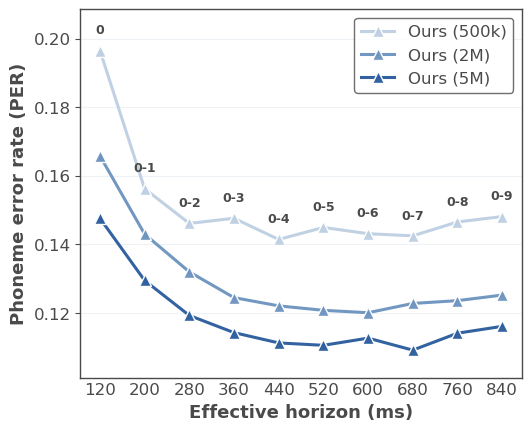

Saved lag_range_ablation_blue.png


In [21]:
lags = ['0', '0-1', '0-2', '0-3', '0-4', '0-5', '0-6', '0-7', '0-8', '0-9']
horizon_ms = np.array([120, 200, 280, 360, 440, 520, 600, 680, 760, 840], dtype=float)
per_500k = np.array([0.1965, 0.15623, 0.14612, 0.14762, 0.14145, 0.14495, 0.14312, 0.1425, 0.14654, 0.14812], dtype=float)
per_2m = np.array([0.1658, 0.1430, 0.1320, 0.1245, 0.1221, 0.1208, 0.1201, 0.1228, 0.12362, 0.12524], dtype=float)
per_5m = np.array([0.1476, 0.1295, 0.1193, 0.1143, 0.1113, 0.1106, 0.1127, 0.1092, 0.11413, 0.11613], dtype=float)

base_ours_blue = "#4E79A7"

lag_range_style = {
    "500k": {"color": "#BFD0E3", "marker": "^", "linestyle": "-"},
    "2M":   {"color": "#6F95BF", "marker": "^", "linestyle": "-"},
    "5M":   {"color": "#2F5F9F", "marker": "^", "linestyle": "-"},
}

lag_ablation_save_path = FIGURES_DIR / 'lag_range_ablation_blue.png'
fig, ax = plt.subplots(figsize=(5.2, 4.2), constrained_layout=True)
fig.patch.set_facecolor(FIGURE_FACE)
style_single_axis(ax, xlabel='Effective horizon (ms)', ylabel='Phoneme error rate (PER)')
ax.grid(True, axis='y', color=GRID_COLOR, linewidth=0.8)
ax.grid(False, axis='x')

series_map = {
    '500k': per_500k,
    '2M': per_2m,
    '5M': per_5m,
}

for label, per_values in series_map.items():
    series_style = lag_range_style[label]
    ax.plot(
        horizon_ms,
        per_values,
        label=f'Ours ({label})',
        color=series_style['color'],
        linestyle=series_style['linestyle'],
        linewidth=2.2,
        marker=series_style['marker'],
        markersize=8,
        markerfacecolor=series_style['color'],
        markeredgecolor='white',
        markeredgewidth=1.0,
        alpha=0.98,
        zorder=3,
    )

for x_value, lag_label, y_value in zip(horizon_ms, lags, np.maximum(per_2m, per_500k)):
    ax.annotate(
        lag_label,
        xy=(x_value, y_value),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=ANNOTATION_FONT_SIZE,
        fontweight='bold',
        color=AXIS_TEXT_COLOR,
    )

y_min = min(per_2m.min(), per_5m.min(), per_500k.min()) - 0.008
y_max = max(per_2m.max(), per_5m.max(), per_500k.max()) + 0.012
ax.set_xlim(horizon_ms.min() - 35, horizon_ms.max() + 35)
ax.set_ylim(y_min, y_max)
ax.set_xticks(horizon_ms)
ax.set_xticklabels([str(int(value)) for value in horizon_ms])

legend = ax.legend(loc='upper right', frameon=True)
style_legend(legend)

plt.show()
fig.savefig(lag_ablation_save_path, dpi=300, bbox_inches='tight')
print(f'Saved {lag_ablation_save_path}')


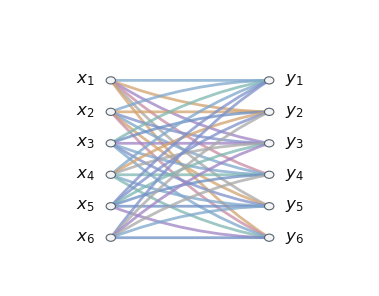

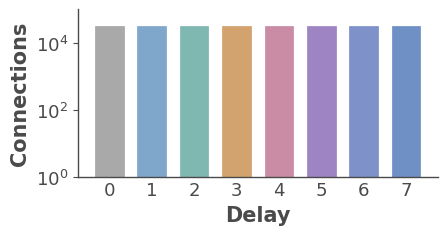

Loaded /home/alex/snn_for_bts/brain_to_text/model_training/logs/final/2026-05-02_18-23-29_440017_snn_pid2956706/checkpoints/delay_assignments_test_split_00/delay_assignments_all_layers.csv
Visualized block 1 to block 2.
Visualized all connections in the top-left 6 x 6 submatrix for the selected block.
Saved delay_wiring_scaffold.png
Saved delay_distribution_scaffold.png (computed from all lags in the selected block)


In [22]:
delay_assignment_csv = None
# Example explicit path:
# delay_assignment_csv = repo_root / 'model_training' / 'logs' / 'snn_final' / 'some_run' / 'checkpoints' / 'delay_assignments_test_split_04' / 'delay_assignments_all_layers.csv'

repo_root = NOTEBOOK_DIR.parent.resolve() if 'repo_root' not in globals() else Path(repo_root).resolve()

blocks_to_plot = None
visualize_n_neurons = 6
max_connections_per_block = 2000
random_seed = 7
wiring_save_path = FIGURES_DIR / 'delay_wiring_scaffold.png'
delay_distribution_save_path = FIGURES_DIR / 'delay_distribution_scaffold.png'

# Separate figure sizing for the two exports.
wiring_figsize = (4.0, 3.0)
wiring_margins = {
    'left': 0.08,
    'right': 0.98,
    'top': 0.98,
    'bottom': 0.06,
}
distribution_figsize = (4.0, 2.5)
distribution_margins = {
    'left': 0.09,
    'right': 0.99,
    'top': 0.95,
    'bottom': 0.28,
}

scaffold_node_facecolor = '#F3F5F7'
scaffold_node_edgecolor = '#59636E'
scaffold_node_radius_large = 0.0105
scaffold_node_radius_small = 0.0130
scaffold_node_label_fontsize_large = 10.5
scaffold_node_label_fontsize_small = 12.0

scaffold_connection_alpha_sampled = 0.36
scaffold_connection_alpha_full = 0.76
scaffold_connection_alpha_default = 0.46
scaffold_connection_width_sampled = 1.35
scaffold_connection_width_full = 2.0
scaffold_connection_width_default = 1.55

scaffold_bar_label_fontsize = 13
scaffold_bar_axis_label_fontsize = 15

delay_palette = {
    0: '#A9A9A9',
    1: '#7FA7CC',
    2: '#7FB7B1',
    3: '#D3A36F',
    4: '#C98CA4',
    5: '#9F84C4',
    6: '#7E91C9',
    7: '#6E90C4',
    8: '#7FA9B4',
    9: '#BB956D',
}


def discover_latest_delay_assignment_csv(root_dir):
    candidates = sorted(
        root_dir.glob('**/delay_assignments_all_layers.csv'),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )
    if not candidates:
        raise FileNotFoundError(
            'No delay_assignments_all_layers.csv file was found under the repository root. '
            'Run export_best_checkpoint_delay_assignments.py first or set delay_assignment_csv explicitly.'
        )
    return candidates[0]


def parse_delay_value(value):
    text = str(value).strip()
    if '|' in text:
        text = text.split('|')[0]
    return int(float(text))


def soften_color(color, blend=0.00):
    base_rgb = np.array(mpl.colors.to_rgb(color), dtype=float)
    return mpl.colors.to_hex(base_rgb * (1.0 - blend) + np.ones(3) * blend)


def build_delay_color_map(delay_values):
    resolved = {}
    remaining = []
    for delay in sorted(delay_values):
        if delay in delay_palette:
            resolved[delay] = soften_color(delay_palette[delay])
        else:
            remaining.append(delay)

    if remaining:
        cmap = mpl.cm.get_cmap('cividis', len(remaining))
        for idx, delay in enumerate(remaining):
            resolved[delay] = soften_color(mpl.colors.to_hex(cmap(idx)))

    return resolved


def draw_connection_curve(ax, x0, y0, x1, y1, color, lw=1.0, alpha=0.2, zorder=1):
    curvature = 0.11 * np.sign(y1 - y0) * (0.35 + abs(y1 - y0))
    ctrl_x = 0.5 * (x0 + x1)
    ctrl_y = 0.5 * (y0 + y1) + curvature
    path = mpl.path.Path(
        [(x0, y0), (ctrl_x, ctrl_y), (x1, y1)],
        [mpl.path.Path.MOVETO, mpl.path.Path.CURVE3, mpl.path.Path.CURVE3],
    )
    patch = mpl.patches.PathPatch(
        path,
        facecolor='none',
        edgecolor=color,
        lw=lw,
        alpha=alpha,
        zorder=zorder,
        capstyle='round',
    )
    ax.add_patch(patch)


def filter_block_df_for_visualization(block_df, n_neurons):
    if n_neurons is None:
        return block_df.copy(), int(block_df['out_channel'].max()) + 1, int(block_df['in_channel'].max()) + 1

    n_neurons = int(n_neurons)
    filtered = block_df[
        (block_df['out_channel'].astype(int) < n_neurons)
        & (block_df['in_channel'].astype(int) < n_neurons)
    ].copy()
    if filtered.empty:
        raise ValueError(f'No rows remain after applying visualize_n_neurons={n_neurons}.')
    return filtered, n_neurons, n_neurons


def draw_node_column(ax, x_center, y_bottom, block_height, n_nodes, show_labels=False, prefix='x'):
    y_positions = np.linspace(y_bottom + block_height - 0.045, y_bottom + 0.045, n_nodes)
    radius = scaffold_node_radius_large if n_nodes > 20 else scaffold_node_radius_small
    label_fontsize = (
        scaffold_node_label_fontsize_large
        if n_nodes > 12
        else scaffold_node_label_fontsize_small
    )
    text_offset = 0.045
    text_x = x_center - text_offset if prefix == 'x' else x_center + text_offset
    text_ha = 'right' if prefix == 'x' else 'left'

    for node_idx, y in enumerate(y_positions):
        circle = mpl.patches.Circle(
            (x_center, y),
            radius,
            facecolor=scaffold_node_facecolor,
            edgecolor=scaffold_node_edgecolor,
            linewidth=0.8,
            zorder=5,
        )
        ax.add_patch(circle)
        if show_labels:
            ax.text(
                text_x,
                y,
                rf'${prefix}_{{{node_idx + 1}}}$',
                ha=text_ha,
                va='center',
                fontsize=label_fontsize,
                color='#111111',
            )

    return y_positions


def plot_connected_block_wiring(ax, block_df, delay_colors, rng, visualize_n_neurons=None):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    ax.set_facecolor('white')

    y_bottom = 0.13
    block_height = 0.66
    x_centers = np.array([0.28, 0.72])

    if visualize_n_neurons is None:
        n_nodes = int(max(block_df['out_channel'].max(), block_df['in_channel'].max())) + 1
    else:
        n_nodes = int(visualize_n_neurons)

    filtered_df, _, _ = filter_block_df_for_visualization(block_df, visualize_n_neurons)
    filtered_df = filtered_df.sort_values(['out_channel', 'in_channel']).reset_index(drop=True)

    if max_connections_per_block is not None and visualize_n_neurons is None and len(filtered_df) > max_connections_per_block:
        sampled_parts = []
        total_rows = len(filtered_df)
        for delay_value, delay_subset in filtered_df.groupby('delay_value', sort=True):
            n_keep = max(1, int(round(max_connections_per_block * len(delay_subset) / total_rows)))
            n_keep = min(n_keep, len(delay_subset))
            sampled_parts.append(delay_subset.sample(n=n_keep, random_state=int(rng.integers(0, 1_000_000))))
        draw_df = pd.concat(sampled_parts, ignore_index=True)
        line_alpha = scaffold_connection_alpha_sampled
        line_width = scaffold_connection_width_sampled
    else:
        draw_df = filtered_df.copy()
        line_alpha = (
            scaffold_connection_alpha_full
            if visualize_n_neurons is not None
            else scaffold_connection_alpha_default
        )
        line_width = (
            scaffold_connection_width_full
            if visualize_n_neurons is not None
            else scaffold_connection_width_default
        )

    left_y = draw_node_column(
        ax,
        x_centers[0],
        y_bottom,
        block_height,
        n_nodes=n_nodes,
        show_labels=visualize_n_neurons is not None,
        prefix='x',
    )
    right_y = draw_node_column(
        ax,
        x_centers[1],
        y_bottom,
        block_height,
        n_nodes=n_nodes,
        show_labels=visualize_n_neurons is not None,
        prefix='y',
    )

    for row in draw_df.itertuples(index=False):
        draw_connection_curve(
            ax,
            x_centers[0],
            left_y[int(row.out_channel)],
            x_centers[1],
            right_y[int(row.in_channel)],
            color=delay_colors[int(row.delay_value)],
            lw=line_width,
            alpha=line_alpha,
            zorder=1,
        )


def plot_delay_distribution(ax, block_df, delay_colors):
    delay_counts = block_df['delay_value'].value_counts().sort_index()
    delay_labels = [str(int(delay_value)) for delay_value in delay_counts.index]
    delay_bar_colors = [delay_colors[int(delay_value)] for delay_value in delay_counts.index]

    ax.bar(
        delay_labels,
        delay_counts.values,
        color=delay_bar_colors,
        edgecolor='white',
        linewidth=0.9,
        width=0.72,
    )
    style_single_axis(ax, xlabel='Delay', ylabel='Connections')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_facecolor('white')
    ax.grid(False)
    ax.set_yscale('log')
    ax.set_ylim(1, 1e5)
    ax.tick_params(axis='x', labelsize=scaffold_bar_label_fontsize)
    ax.tick_params(axis='y', labelsize=scaffold_bar_label_fontsize)
    ax.xaxis.label.set_size(scaffold_bar_axis_label_fontsize)
    ax.yaxis.label.set_size(scaffold_bar_axis_label_fontsize)


if delay_assignment_csv is None:
    delay_assignment_csv = discover_latest_delay_assignment_csv(repo_root)
else:
    delay_assignment_csv = Path(delay_assignment_csv)
    if not delay_assignment_csv.is_absolute():
        delay_assignment_csv = (repo_root / delay_assignment_csv).resolve()

if not delay_assignment_csv.exists():
    raise FileNotFoundError(f'Delay assignment CSV not found: {delay_assignment_csv}')

delay_df = pd.read_csv(delay_assignment_csv)
if 'selected_lags' in delay_df.columns:
    delay_df['delay_value'] = delay_df['selected_lags'].apply(parse_delay_value)
elif 'lag' in delay_df.columns:
    delay_df['delay_value'] = delay_df['lag'].apply(parse_delay_value)
else:
    raise KeyError('Expected either a selected_lags or lag column in the delay assignment CSV.')

if 'block_idx' not in delay_df.columns:
    delay_df['block_idx'] = 0

delay_df['block_idx'] = delay_df['block_idx'].astype(int)
delay_df['out_channel'] = delay_df['out_channel'].astype(int)
delay_df['in_channel'] = delay_df['in_channel'].astype(int)

if blocks_to_plot is not None:
    delay_df = delay_df[delay_df['block_idx'].isin(blocks_to_plot)].copy()

if delay_df.empty:
    raise ValueError('No rows remain after filtering the delay assignment CSV.')

available_block_ids = sorted(delay_df['block_idx'].unique())
selected_block_id = int(available_block_ids[0])
selected_block_df = delay_df[delay_df['block_idx'] == selected_block_id].copy()

delay_colors = build_delay_color_map(delay_df['delay_value'].dropna().astype(int).unique())
rng = np.random.default_rng(random_seed)

wiring_fig, ax_wiring = plt.subplots(figsize=wiring_figsize)
wiring_fig.patch.set_facecolor('white')
wiring_fig.subplots_adjust(**wiring_margins)
plot_connected_block_wiring(
    ax_wiring,
    selected_block_df,
    delay_colors=delay_colors,
    rng=rng,
    visualize_n_neurons=visualize_n_neurons,
)
plt.show()
wiring_fig.savefig(wiring_save_path, dpi=300, bbox_inches='tight')

distribution_fig, ax_dist = plt.subplots(figsize=distribution_figsize)
distribution_fig.patch.set_facecolor('white')
distribution_fig.subplots_adjust(**distribution_margins)
plot_delay_distribution(ax_dist, selected_block_df, delay_colors)
plt.show()
distribution_fig.savefig(delay_distribution_save_path, dpi=300, bbox_inches='tight')

print(f'Loaded {delay_assignment_csv}')
print(f'Visualized block {selected_block_id + 1} to block {selected_block_id + 2}.')
if visualize_n_neurons is not None:
    print(f'Visualized all connections in the top-left {int(visualize_n_neurons)} x {int(visualize_n_neurons)} submatrix for the selected block.')
else:
    print('Visualized all connections in the selected block.')
print(f'Saved {wiring_save_path}')
print(f'Saved {delay_distribution_save_path} (computed from all lags in the selected block)')


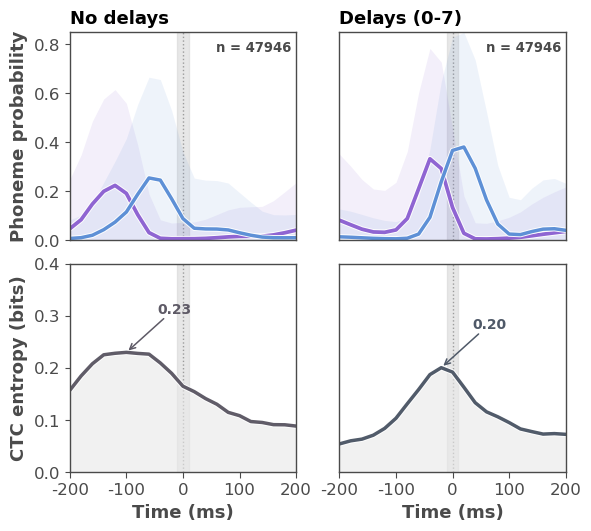

{
  "num_gru_trials": 1884,
  "num_lagged_snn_trials": 1884,
  "num_no_lag_snn_trials": 1884,
  "num_shared_trials": 1884,
  "num_trimmed_length_trials": 1884,
  "window_radius": 10,
  "window_size": 21,
  "candidate_transitions": 48944,
  "used_transitions": 47946,
  "skipped_edge_transitions": 998,
  "frame_step_seconds": 0.02,
  "files_read": {
    "gru_reference": "/home/alex/snn_for_bts/brain_to_text/model_training/logs/rnn_final/2026-04-11_08-15-05_844366_rnn_pid398260/checkpoints/daywise_test_split_04_validation_export.pt",
    "lagged_snn": "/home/alex/snn_for_bts/brain_to_text/model_training/logs/snn_final/2026-04-13_12-38-31_420690_snn_pid89558/checkpoints/daywise_test_split_04_validation_export.pt",
    "no_lag_snn": "/home/alex/snn_for_bts/brain_to_text/model_training/logs/snn_lags_ablation1/2026-04-14_11-31-15_714173_snn_pid2420/checkpoints/daywise_test_split_04_validation_export.pt"
  },
  "figure_path": "/home/alex/snn_for_bts/brain_to_text/analyses/lag_vs_nolag_boundary

In [23]:
import os
import json
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Mapping, MutableMapping

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import torch

BLANK_ID = 0
EPS = 1e-8

# You can point these at either a rich validation export or a ctc_evidence file.
# If you pass a ctc_evidence/validation_run_XXXX.pt path, the helper below will
# resolve the sibling checkpoints/daywise_test_split_*_validation_export.pt file.
GRU_REFERENCE_SOURCE = (
    repo_root
    / 'model_training/logs/rnn_final/2026-04-11_08-15-05_844366_rnn_pid398260/ctc_evidence/validation_run_0030.pt'
)
LAGGED_SNN_SOURCE = (
    repo_root
    / 'model_training/logs/snn_final/2026-04-13_12-38-31_420690_snn_pid89558/ctc_evidence/validation_run_0030.pt'
)
NO_LAG_SNN_SOURCE = (
    repo_root
    / 'model_training/logs/snn_lags_ablation1/2026-04-14_11-31-15_714173_snn_pid2420/ctc_evidence/validation_run_0030.pt'
)

BOUNDARY_WINDOW_RADIUS = 10
FRAME_STEP_SECONDS = 0.02
BOUNDARY_BAND_HALF_WIDTH_SECONDS = FRAME_STEP_SECONDS / 2.0
boundary_analysis_save_path = FIGURES_DIR / 'lag_vs_nolag_boundary_analysis.png'
boundary_analysis_summary_path = NOTEBOOK_DIR / 'lag_vs_nolag_boundary_analysis_summary.json'

base_ours_blue = '#4E79A7'
base_rgb = np.array(mpl.colors.to_rgb(base_ours_blue))
boundary_model_style = {
    'No delays': {
        'entropy_color': '#5E5A66',
        'linewidth': 2.5,
    },
    'Delays (0-7)': {
        'entropy_color': '#4F5968',
        'linewidth': 2.5,
    },
}
phoneme_role_style = {
    'left_prob': {
        'label': 'Left phoneme',
        'color': '#8E63D2',
        'linewidth_scale': 1.08,
        'band_alpha': 0.10,
    },
    'right_prob': {
        'label': 'Right phoneme',
        'color': '#5C8FD6',
        'linewidth_scale': 1.0,
        'band_alpha': 0.10,
    },
}


@dataclass(frozen=True)
class TransitionEvent:
    trial_id: str
    center_frame: int
    left_class: int
    right_class: int
    left_end_frame: int
    right_start_frame: int
    num_blank_runs_between: int


def ensure_file_exists(path: Path, label: str) -> None:
    if not path.exists():
        raise FileNotFoundError(f'Missing {label}: {path}')
    if not path.is_file():
        raise FileNotFoundError(f'Expected {label} to be a file, got: {path}')


def resolve_validation_export_path(source_path: Path) -> Path:
    source_path = Path(source_path)
    if not source_path.is_absolute():
        source_path = (repo_root / source_path).resolve()

    if source_path.name.startswith('daywise_test_split_') and source_path.name.endswith('_validation_export.pt'):
        ensure_file_exists(source_path, 'validation export')
        return source_path

    if source_path.parent.name == 'ctc_evidence' and source_path.suffix == '.pt':
        run_root = source_path.parent.parent
        checkpoint_candidates = sorted(run_root.glob('checkpoints/daywise_test_split_*_validation_export.pt'))
        if not checkpoint_candidates:
            raise FileNotFoundError(
                'Could not find a sibling daywise_test_split_*_validation_export.pt for '
                f'{source_path}. The boundary analysis needs the richer validation export.'
            )
        return checkpoint_candidates[0]

    ensure_file_exists(source_path, 'validation export source')
    return source_path


def as_cpu_tensor(value, *, dtype=None) -> torch.Tensor:
    tensor = value.detach().cpu() if isinstance(value, torch.Tensor) else torch.as_tensor(value)
    if dtype is not None:
        tensor = tensor.to(dtype)
    return tensor


def slice_trial_tensor(value, length: int, *, dtype=None) -> torch.Tensor:
    tensor = as_cpu_tensor(value, dtype=dtype)
    if tensor.ndim == 0:
        return tensor
    return tensor[:length]


def load_trial_export(path: Path, *, require_alignment: bool) -> Dict[str, object]:
    ensure_file_exists(path, 'trial export')
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if 'trials' not in payload:
        raise KeyError(
            f"Expected a per-trial export with a 'trials' field at {path}. "
            'Use the validation export written by the daywise evaluation flow.'
        )

    trials: MutableMapping[str, Dict[str, object]] = {}
    duplicate_ids: List[str] = []

    for raw_record in payload['trials']:
        record = dict(raw_record)
        trial_id = record.get('trial_id')
        if trial_id is None:
            raise KeyError(f'Found a trial without trial_id in {path}')
        if trial_id in trials:
            duplicate_ids.append(trial_id)
            continue

        input_length = int(record.get('input_length', len(record.get('predictions', []))))
        parsed = {
            'trial_id': trial_id,
            'input_length': input_length,
            'logits': (
                slice_trial_tensor(record['logits'], input_length, dtype=torch.float32)
                if record.get('logits') is not None
                else None
            ),
            'probs': (
                slice_trial_tensor(
                    record.get('probs', record.get('probabilities')),
                    input_length,
                    dtype=torch.float32,
                )
                if record.get('probs', record.get('probabilities')) is not None
                else None
            ),
        }

        if require_alignment:
            if 'aligned_target' not in record:
                raise KeyError(f"Missing 'aligned_target' in {path} for trial {trial_id}")
            parsed['aligned_target'] = slice_trial_tensor(
                record['aligned_target'],
                input_length,
                dtype=torch.long,
            )

        trials[trial_id] = parsed

    if duplicate_ids:
        sample = sorted(set(duplicate_ids))[:5]
        raise ValueError(f'Duplicate trial_id entries found in {path}; sample={sample}')

    return {
        'path': path,
        'phoneme_classes': payload.get('phoneme_classes'),
        'trials': trials,
    }


def verify_shared_vocab(*payloads: Mapping[str, object]) -> None:
    vocab = None
    for payload in payloads:
        cur = payload.get('phoneme_classes')
        if cur is None:
            continue
        cur_list = list(cur)
        if vocab is None:
            vocab = cur_list
            continue
        if vocab != cur_list:
            raise ValueError('Model exports do not share the same phoneme_classes ordering')


def get_probabilities(trial_record: Mapping[str, object], common_len: int) -> torch.Tensor:
    probs = trial_record.get('probs')
    if probs is not None:
        probs = as_cpu_tensor(probs, dtype=torch.float32)[:common_len]
    else:
        logits = trial_record.get('logits')
        if logits is None:
            raise KeyError(
                f"Trial {trial_record.get('trial_id')} is missing both 'probs' and 'logits'"
            )
        probs = torch.softmax(as_cpu_tensor(logits, dtype=torch.float32)[:common_len], dim=-1)

    if probs.ndim != 2:
        raise ValueError(
            f"Expected 2D framewise probabilities for trial {trial_record.get('trial_id')}, "
            f'got shape {tuple(probs.shape)}'
        )
    return probs


def compute_entropy(probs: torch.Tensor, eps: float = EPS) -> torch.Tensor:
    safe_probs = probs.clamp_min(eps)
    return -(safe_probs * safe_probs.log2()).sum(dim=-1)


def run_length_encode(sequence: torch.Tensor):
    if sequence.numel() == 0:
        return []

    values = sequence.to(torch.long).tolist()
    runs = []
    start = 0
    current = values[0]

    for idx in range(1, len(values) + 1):
        if idx == len(values) or values[idx] != current:
            runs.append((start, idx - 1, current))
            if idx < len(values):
                start = idx
                current = values[idx]
    return runs


def extract_gru_transition_events(
    trial_id: str,
    aligned_target: torch.Tensor,
    *,
    blank_id: int = BLANK_ID,
    ignore_same_phoneme_repeats: bool = True,
):
    runs = run_length_encode(aligned_target)
    events = []

    for run_idx, (_, left_end, left_class) in enumerate(runs):
        if left_class == blank_id:
            continue

        next_idx = run_idx + 1
        blank_runs_between = 0
        while next_idx < len(runs) and runs[next_idx][2] == blank_id:
            blank_runs_between += 1
            next_idx += 1

        if next_idx >= len(runs):
            continue

        right_start, _, right_class = runs[next_idx]
        if right_class == blank_id:
            continue
        if ignore_same_phoneme_repeats and right_class == left_class:
            continue
        if right_start <= left_end:
            continue

        center_frame = int(round((left_end + right_start) / 2.0))
        events.append(
            TransitionEvent(
                trial_id=trial_id,
                center_frame=center_frame,
                left_class=int(left_class),
                right_class=int(right_class),
                left_end_frame=int(left_end),
                right_start_frame=int(right_start),
                num_blank_runs_between=int(blank_runs_between),
            )
        )

    return events


def summarize_curve_stack(curves: List[torch.Tensor]) -> Dict[str, torch.Tensor]:
    if not curves:
        raise ValueError('No curves were accumulated')
    stacked = torch.stack(curves, dim=0)
    return {
        'mean': stacked.mean(dim=0),
        'std': stacked.std(dim=0, unbiased=False),
    }


def analyze_transition_curves(
    gru_reference: Mapping[str, object],
    lagged_snn: Mapping[str, object],
    no_lag_snn: Mapping[str, object],
    *,
    window_radius: int,
    blank_id: int = BLANK_ID,
):
    gru_trials = gru_reference['trials']
    lagged_trials = lagged_snn['trials']
    no_lag_trials = no_lag_snn['trials']

    shared_trial_ids = sorted(set(gru_trials) & set(lagged_trials) & set(no_lag_trials))
    if not shared_trial_ids:
        raise ValueError('No shared trial_id values were found across the three exports')

    offsets = torch.arange(-window_radius, window_radius + 1, dtype=torch.int64)
    lagged_left_curves = []
    lagged_right_curves = []
    lagged_entropy_curves = []
    no_lag_left_curves = []
    no_lag_right_curves = []
    no_lag_entropy_curves = []

    trimmed_length_trials = 0
    candidate_transition_count = 0
    used_transition_count = 0
    skipped_edge_transition_count = 0

    for trial_id in shared_trial_ids:
        gru_trial = gru_trials[trial_id]
        lagged_trial = lagged_trials[trial_id]
        no_lag_trial = no_lag_trials[trial_id]

        lengths = (
            int(gru_trial['input_length']),
            int(lagged_trial['input_length']),
            int(no_lag_trial['input_length']),
        )
        common_len = min(lengths)
        if common_len <= 0:
            continue
        if len(set(lengths)) != 1:
            trimmed_length_trials += 1

        aligned_target = as_cpu_tensor(gru_trial['aligned_target'], dtype=torch.long)[:common_len]
        lagged_probs = get_probabilities(lagged_trial, common_len)
        no_lag_probs = get_probabilities(no_lag_trial, common_len)

        lagged_entropy = compute_entropy(lagged_probs)
        no_lag_entropy = compute_entropy(no_lag_probs)

        for event in extract_gru_transition_events(trial_id, aligned_target, blank_id=blank_id):
            candidate_transition_count += 1

            center = event.center_frame
            start = center - window_radius
            end = center + window_radius
            if start < 0 or end >= common_len:
                skipped_edge_transition_count += 1
                continue

            frame_slice = slice(start, end + 1)
            left_class = event.left_class
            right_class = event.right_class

            lagged_window = lagged_probs[frame_slice]
            no_lag_window = no_lag_probs[frame_slice]

            lagged_left_curves.append(lagged_window[:, left_class])
            lagged_right_curves.append(lagged_window[:, right_class])
            lagged_entropy_curves.append(lagged_entropy[frame_slice])

            no_lag_left_curves.append(no_lag_window[:, left_class])
            no_lag_right_curves.append(no_lag_window[:, right_class])
            no_lag_entropy_curves.append(no_lag_entropy[frame_slice])

            used_transition_count += 1

    return {
        'offsets': offsets,
        'curves': {
            'No delays': {
                'left_prob': summarize_curve_stack(no_lag_left_curves),
                'right_prob': summarize_curve_stack(no_lag_right_curves),
                'entropy': summarize_curve_stack(no_lag_entropy_curves),
            },
            'Delays (0-7)': {
                'left_prob': summarize_curve_stack(lagged_left_curves),
                'right_prob': summarize_curve_stack(lagged_right_curves),
                'entropy': summarize_curve_stack(lagged_entropy_curves),
            },
        },
        'summary': {
            'num_gru_trials': len(gru_trials),
            'num_lagged_snn_trials': len(lagged_trials),
            'num_no_lag_snn_trials': len(no_lag_trials),
            'num_shared_trials': len(shared_trial_ids),
            'num_trimmed_length_trials': trimmed_length_trials,
            'window_radius': int(window_radius),
            'window_size': int(2 * window_radius + 1),
            'candidate_transitions': int(candidate_transition_count),
            'used_transitions': int(used_transition_count),
            'skipped_edge_transitions': int(skipped_edge_transition_count),
            'frame_step_seconds': FRAME_STEP_SECONDS,
            'files_read': {
                'gru_reference': str(gru_reference['path']),
                'lagged_snn': str(lagged_snn['path']),
                'no_lag_snn': str(no_lag_snn['path']),
            },
        },
    }


def plot_mean_curve(ax, x_values, stats, *, color, lw, label=None, band_alpha=0.10, band_color=None):
    mean = stats['mean'].cpu().numpy()
    std = stats['std'].cpu().numpy()
    lower = np.clip(mean - std, a_min=0.0, a_max=None)
    upper = mean + std
    if band_color is None:
        band_color = color
    if band_alpha > 0.0:
        ax.fill_between(
            x_values,
            lower,
            upper,
            color=band_color,
            alpha=band_alpha,
            linewidth=0,
            zorder=1,
        )
    line = ax.plot(
        x_values,
        mean,
        color=color,
        linewidth=lw,
        linestyle='-',
        label=label,
        alpha=0.99,
        zorder=2,
        solid_capstyle='round',
        solid_joinstyle='round',
    )[0]
    line.set_path_effects([
        pe.Stroke(linewidth=lw + 1.4, foreground='white', alpha=0.95),
        pe.Normal(),
    ])


def add_boundary_marker(ax, *, show_band=True):
    if show_band:
        ax.axvspan(
            -BOUNDARY_BAND_HALF_WIDTH_SECONDS,
            BOUNDARY_BAND_HALF_WIDTH_SECONDS,
            color='#D7D7D7',
            alpha=0.6,
            zorder=0,
        )
    ax.axvline(0.0, color='#9B9B9B', linewidth=1.0, linestyle=':', zorder=0.1)


def make_boundary_figure(analysis: Mapping[str, object]):
    offsets = analysis['offsets'].cpu().numpy()
    x_seconds = offsets * FRAME_STEP_SECONDS
    curves = analysis['curves']
    model_order = ['No delays', 'Delays (0-7)']

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(5.8, 5.2),
        sharex='col',
        constrained_layout=True,
    )
    fig.patch.set_facecolor('white')

    x_limit = BOUNDARY_WINDOW_RADIUS * FRAME_STEP_SECONDS
    tick_values = np.linspace(-x_limit, x_limit, 5)

    for col_idx, model_label in enumerate(model_order):
        ax_prob = axes[0, col_idx]
        ax_ent = axes[1, col_idx]
        model_curves = curves[model_label]
        model_style = boundary_model_style[model_label]

        style_single_axis(ax_prob, ylabel='Phoneme probability' if col_idx == 0 else None)
        style_single_axis(
            ax_ent,
            xlabel=None,
            ylabel='CTC entropy (bits)' if col_idx == 0 else None,
        )

        if col_idx == 1:
            for ax in (ax_prob, ax_ent):
                ax.set_ylabel(None)
                ax.tick_params(axis='y', left=False, labelleft=False)
                ax.spines['left'].set_visible(True)

        ax_prob.set_facecolor('white')
        ax_prob.grid(False)
        add_boundary_marker(ax_prob, show_band=True)
        ax_prob.set_xlim(-x_limit, x_limit)

        ax_ent.set_facecolor('white')
        ax_ent.grid(False)
        add_boundary_marker(ax_ent, show_band=True)
        ax_ent.set_xlim(-x_limit, x_limit)

        for curve_key in ('left_prob', 'right_prob'):
            role_style = phoneme_role_style[curve_key]
            plot_mean_curve(
                ax_prob,
                x_seconds,
                model_curves[curve_key],
                color=role_style['color'],
                lw=model_style['linewidth'] * role_style['linewidth_scale'],
                label=role_style['label'],
                band_alpha=role_style['band_alpha'],
                band_color=role_style['color'],
            )

        entropy_stats = {
            'mean': model_curves['entropy']['mean'],
            'std': model_curves['entropy']['std'],
        }
        entropy_line_stats = {
            'mean': entropy_stats['mean'],
            'std': entropy_stats['std'],
        }
        entropy_mean = entropy_line_stats['mean'].cpu().numpy()
        ax_ent.fill_between(
            x_seconds,
            0.0,
            entropy_mean,
            color='#E9E9E9',
            alpha=0.6,
            linewidth=0,
            zorder=0.2,
        )
        plot_mean_curve(
            ax_ent,
            x_seconds,
            entropy_line_stats,
            color=model_style['entropy_color'],
            lw=model_style['linewidth'],
            label='Entropy',
            band_alpha=0.0,
            band_color='#E9E9E9',
        )

        ax_prob.set_title(model_label, fontweight='bold', loc='left')
        ax_prob.set_ylim(0.0, 0.85)
        ax_ent.set_ylim(0.0, 0.4)
        ax_ent.set_xticks(tick_values)
        ax_ent.set_xticklabels([str(int(round(value * 1000))) for value in tick_values])
        ax_ent.tick_params(axis='x', length=4)
        ax_ent.set_yticks(np.linspace(0.0, 0.4, 5))
        ax_ent.set_xlabel('Time (ms)', fontweight='bold')

        peak_idx = int(np.argmax(entropy_mean))
        peak_x = float(x_seconds[peak_idx])
        peak_y = float(entropy_mean[peak_idx])
        text_dx = 0.055 if peak_x <= 0 else -0.055
        text_ha = 'left' if peak_x <= 0 else 'right'
        ax_ent.annotate(
            f'{peak_y:.2f}',
            xy=(peak_x, peak_y),
            xytext=(peak_x + text_dx, min(0.385, peak_y + 0.07)),
            textcoords='data',
            ha=text_ha,
            va='bottom',
            fontsize=ANNOTATION_FONT_SIZE + 1,
            fontweight='bold',
            color=model_style['entropy_color'],
            arrowprops={
                'arrowstyle': '->',
                'color': model_style['entropy_color'],
                'linewidth': 1.1,
                'shrinkA': 0.0,
                'shrinkB': 2.0,
            },
        )

    n_examples = int(analysis['summary']['used_transitions'])
    for col_idx in range(2):
        axes[0, col_idx].text(
            0.98,
            0.96,
            f'n = {n_examples}',
            transform=axes[0, col_idx].transAxes,
            ha='right',
            va='top',
            fontsize=9.5,
            fontweight='bold',
            color=AXIS_TEXT_COLOR,
        )
    return fig


gru_reference_export = resolve_validation_export_path(GRU_REFERENCE_SOURCE)
lagged_snn_export = resolve_validation_export_path(LAGGED_SNN_SOURCE)
no_lag_snn_export = resolve_validation_export_path(NO_LAG_SNN_SOURCE)

gru_reference = load_trial_export(gru_reference_export, require_alignment=True)
lagged_snn = load_trial_export(lagged_snn_export, require_alignment=False)
no_lag_snn = load_trial_export(no_lag_snn_export, require_alignment=False)
verify_shared_vocab(gru_reference, lagged_snn, no_lag_snn)

boundary_analysis = analyze_transition_curves(
    gru_reference,
    lagged_snn,
    no_lag_snn,
    window_radius=BOUNDARY_WINDOW_RADIUS,
)

fig = make_boundary_figure(boundary_analysis)
plt.show()
fig.savefig(boundary_analysis_save_path, dpi=300, bbox_inches='tight')

summary_payload = boundary_analysis['summary']
summary_payload['figure_path'] = str(Path(boundary_analysis_save_path).resolve())
summary_payload['figure_layout'] = 'two-column separate lag vs no-delay panels'
summary_payload['resolved_exports'] = {
    'gru_reference': str(gru_reference_export),
    'lagged_snn': str(lagged_snn_export),
    'no_lag_snn': str(no_lag_snn_export),
}
Path(boundary_analysis_summary_path).write_text(json.dumps(summary_payload, indent=2), encoding='utf-8')

print(json.dumps(summary_payload, indent=2))
print(f'Saved {boundary_analysis_save_path}')
print(f'Saved {boundary_analysis_summary_path}')
